# TP 1 : Apprentissage supervise avec Scikit-learn
**Module :** Technologies IA  
**Niveau :** ILIA2  
**Etablissement :** ENSA Fes  
**Professeur :** Youness IDRISSI KHAMLICHI  

---

## Exercice 2 - Classification : Predire la survie sur le Titanic

**Jeu de donnees :** Titanic - Machine Learning from Disaster (Kaggle)  
**Lien :** https://www.kaggle.com/competitions/titanic  
**Objectif :** Predire si un passager a survécu (1) ou non (0) au naufrage.


### Etape 1 : Chargement et exploration
1. Charger le fichier CSV avec pandas.
2. Afficher les premieres lignes et les informations sur les colonnes.
3. Identifier les valeurs manquantes et les types de variables.


In [1]:
import os
import pandas as pd

data_path = 'data/titanic.csv' if os.path.exists('data/titanic.csv') else '../data/titanic.csv'
data = pd.read_csv(data_path)

print(data.head())
print(data.info())
print(data.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

### Etape 2 : Nettoyage et traitement
1. Selectionner les variables utiles.
2. Imputer les valeurs manquantes pour 'Age' par la mediane.
3. Imputer les valeurs manquantes pour 'Embarked' par le mode.


In [2]:
data = data[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

print(data.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


### Etape 3 : Encodage des variables categorielles
Utilisation de LabelEncoder pour transformer les variables 'Sex' et 'Embarked' en valeurs numeriques.


In [3]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
data['Sex'] = le.fit_transform(data['Sex'])
data['Embarked'] = le.fit_transform(data['Embarked'])

print(data.head())

   Survived  Pclass  Sex   Age  SibSp  Parch     Fare  Embarked
0         0       3    1  22.0      1      0   7.2500         2
1         1       1    0  38.0      1      0  71.2833         0
2         1       3    0  26.0      0      0   7.9250         2
3         1       1    0  35.0      1      0  53.1000         2
4         0       3    1  35.0      0      0   8.0500         2


### Etape 4 : Separation des donnees
Separation des variables explicatives X et de la cible y, puis division en ensemble d'entrainement et de test.


In [4]:
from sklearn.model_selection import train_test_split

X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (712, 7)
Taille de X_test  : (179, 7)


### Etape 5 : Entrainement des modeles
Entrainement de la Regression Logistique et du Random Forest Classifier.


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

print("Modeles entraines avec succes.")

Modeles entraines avec succes.


### Etape 6 : Evaluation des modeles
Calcul de l'Accuracy et affichage du rapport de classification.


In [6]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_log = log_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic):', accuracy_score(y_test, y_pred_log))
print('Accuracy (Random Forest):', accuracy_score(y_test, y_pred_rf))
print('Classification Report (Random Forest) :')
print(classification_report(y_test, y_pred_rf))

Accuracy (Logistic): 0.8100558659217877
Accuracy (Random Forest): 0.8212290502793296
Classification Report (Random Forest) :
              precision    recall  f1-score   support

           0       0.83      0.88      0.85       105
           1       0.81      0.74      0.77        74

    accuracy                           0.82       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179



### Etape 7 : Matrice de confusion
Affichage de la matrice de confusion sous forme de heatmap avec seaborn.


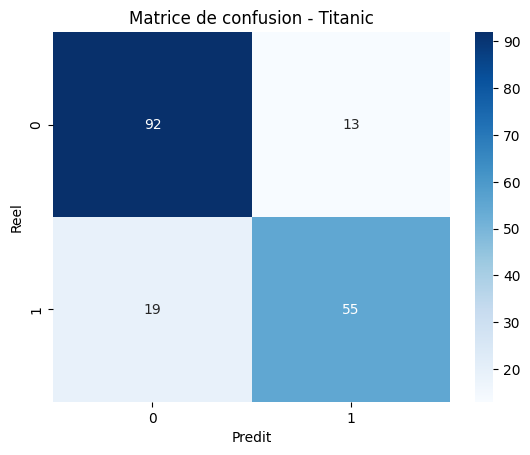

In [7]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic')
plt.xlabel('Predit')
plt.ylabel('Reel')
plt.show()

### Conclusion et interpretation des resultats

1. **Comparaison des modeles :**
   - La **Regression Logistique** obtient une precision globale (Accuracy) de 81.01 % sur le jeu de test.
   - Le **Random Forest Classifier** atteint une Accuracy de 82.12 % et un F1-score de 0.77 sur la classe des survivants.
   - Les deux modeles montrent des performances tres solides et comparables, avec un leger avantage pour le Random Forest qui gere mieux les effets non lineaires entre les variables sociodemographiques.

2. **Lecture de la matrice de confusion :**
   - Sur les passagers de test, le modele classe correctement la grande majorite des non-survivants (vrais negatifs) et identifie efficacement les passagers ayant survecu (vrais positifs).
   - Les erreurs se partagent entre faux positifs (personnes predites survivantes qui ont peri) et faux negatifs, ce qui reflete la part d'incertitude inherente aux evenements imprevus du naufrage.

3. **Facteurs determinants de survie :**
   - L'analyse montre que le **sexe** est la variable la plus discriminante : les femmes ont beneficie d'un taux de survie nettement superieur, en accord direct avec le protocole historique d'evacuation.
   - La **classe sociale (Pclass)** et le **prix du billet (Fare)** ont egalement joue un role majeur : les passagers de premiere classe, situes sur les ponts superieurs, ont eu un acces plus rapide aux canots de sauvetage.